# 05 · Reconstruct COVID data and compare two counties

**Requirements 5 and 6 · 5 + 15 points**

**Sources verified:** both full-size yearly files were extracted from the original `data/2 yearly.zip`. No records were sampled. SHA-256 and byte-size checks reproduce the original inputs. Run `python tools/prepare_data.py` before this notebook in a fresh checkout.

This notebook combines source reconstruction and the required `matplotlib.pyplot` **2 × 2** visualization to satisfy the instruction to submit five notebooks for the six Python requirements.

Inspection confirmed **1,341,647 case records for 2020** and **938,226 for 2021**. `EventDate` falls entirely in the corresponding year, so the partitions do not overlap. Each yearly source has a unique record ID; 2020 calls it `ObjectId2`, and 2021 calls it `ObjectId`. The 2020 `OBJECTID` column is entirely empty and is removed only after checking that fact. All remaining source columns are retained in the combined case-record CSV, with source-file and source-year provenance. String missing-value representations are normalized by pandas; the original byte-for-byte files remain in the archive.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'config').is_dir() else Path.cwd().parent
assert (ROOT / 'config/assignment.json').is_file(), 'Open from the repository or notebooks directory.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dv_assignment.data import config
from dv_assignment.data import rebuild_case_records, rebuilt_county, compare_sources, audit_daily_series, daily_preview
from dv_assignment import charts
import json


## Rebuild from both originals

The source is Florida case-level data. Use `County`, `EventDate` (`%m/%d/%Y`), and each source-local record ID. `ChartDate` and `Case1` are different fields and are not substituted. The reconstruction checks every source ID, year, and county/date key. The `Unknown` county category is retained in the source and excluded only when selecting a specific named county.

The adapter counts records by county and event day and verifies that all **2,279,873** input records reconcile to the resulting counts. There are **three missing `Case_` flags in 2021**; these rows are retained as supplied in the case-only file and reported in the audit. Every nonmissing case flag is `Yes`. No negative counts, missing event dates, or missing county identifiers are silently removed.

In [2]:
settings = config()['raw_covid']
source = rebuild_case_records(settings)
display(source.head())
print(source.attrs['source_audit'])
assert source.daily_cases.sum() == sum(x['case_records'] for x in source.attrs['source_audit'])
output = ROOT / 'data' / 'derived'
output.mkdir(exist_ok=True, parents=True)
source.to_csv(output / 'reconstructed_covid.csv', index=False, date_format='%Y-%m-%d')
(output / 'reconstruction_audit.json').write_text(json.dumps(source.attrs['source_audit'], indent=2))

,state,county,date,daily_cases
0,Florida,Alachua,2020-02-26,1
1,Florida,Alachua,2020-02-28,1
2,Florida,Alachua,2020-03-01,3
3,Florida,Alachua,2020-03-03,1
4,Florida,Alachua,2020-03-05,2


[{'source': 'data/2020 Cases only.csv', 'case_records': 1341647, 'source_year': 2020, 'missing_case_flags_retained': 0, 'unique_source_record_ids': 1341647}, {'source': 'data/2021 Cases only.csv', 'case_records': 938226, 'source_year': 2021, 'missing_case_flags_retained': 3, 'unique_source_record_ids': 938226}]


366

## Extract Broward and Palm Beach from that reconstructed source

The average policy is explicit in the configuration: an 8-observation trailing average, including the current observation and partial initial windows, following the supplied consolidated workbook. Confirm any additional module-specific instructions. Calculate over the observed rows, then introduce missing calendar dates as gaps for display. Do not replace missing dates with zero without evidence that the course intends that interpretation.

In [3]:
broward = rebuilt_county(source, 'Broward', settings['moving_average'])
palm_beach = rebuilt_county(source, 'Palm Beach', settings['moving_average'])
for county in [broward, palm_beach]:
    print({key: value for key, value in county.attrs.items() if key != 'unlisted_dates'})
    display(daily_preview(county, rows=10))

{'source_audit': [{'source': 'data/2020 Cases only.csv', 'case_records': 1341647, 'source_year': 2020, 'missing_case_flags_retained': 0, 'unique_source_record_ids': 1341647}, {'source': 'data/2021 Cases only.csv', 'case_records': 938226, 'source_year': 2021, 'missing_case_flags_retained': 3, 'unique_source_record_ids': 938226}], 'combined_case_records_path': 'data/derived/combined_case_records.csv', 'county': 'Broward', 'state': 'Florida', 'average_definition': '8-observation trailing mean · partial initial windows', 'missing_calendar_days': 24, 'source': '2020 Cases only.csv + 2021 Cases only.csv', 'average_supplied': False, 'negative_daily_revisions': 0}


,daily_cases,moving_average
date,,
2020-01-01 00:00:00,4,4.00
2020-01-02 00:00:00,2,3.00
2020-01-03 00:00:00,Not listed,Not listed
2020-01-04 00:00:00,3,3.00
2020-01-05 00:00:00,Not listed,Not listed
2020-01-06 00:00:00,1,2.50
2020-01-07 00:00:00,2,2.40
2020-01-08 00:00:00,Not listed,Not listed
2020-01-09 00:00:00,Not listed,Not listed


{'source_audit': [{'source': 'data/2020 Cases only.csv', 'case_records': 1341647, 'source_year': 2020, 'missing_case_flags_retained': 0, 'unique_source_record_ids': 1341647}, {'source': 'data/2021 Cases only.csv', 'case_records': 938226, 'source_year': 2021, 'missing_case_flags_retained': 3, 'unique_source_record_ids': 938226}], 'combined_case_records_path': 'data/derived/combined_case_records.csv', 'county': 'Palm Beach', 'state': 'Florida', 'average_definition': '8-observation trailing mean · partial initial windows', 'missing_calendar_days': 37, 'source': '2020 Cases only.csv + 2021 Cases only.csv', 'average_supplied': False, 'negative_daily_revisions': 0}


,daily_cases,moving_average
date,,
2020-01-01 00:00:00,2,2.00
2020-01-02 00:00:00,Not listed,Not listed
2020-01-03 00:00:00,Not listed,Not listed
2020-01-04 00:00:00,1,1.50
2020-01-05 00:00:00,1,1.33
2020-01-06 00:00:00,Not listed,Not listed
2020-01-07 00:00:00,Not listed,Not listed
2020-01-08 00:00:00,Not listed,Not listed
2020-01-09 00:00:00,Not listed,Not listed


## Missing-value check and treatment

Both original case files have complete county, event-date and nonempty record-ID fields. Grouped county/day counts also have no missing counts. The NaNs in the displayed series come from inserting dates with no matching case records. This is separate from the three missing `Case_` flags retained in the input.

The audit below identifies every inserted date and verifies that no observed daily count or calculated mean is null. Previews say **Not listed** rather than displaying NaN. For this submission, preserve gaps and the documented observation-window mean. If the module explicitly guarantees complete case coverage and defines absent dates as zero, an alternative zero-filled daily series must recompute its mean on that calendar and disclose the changed definition; do not use a blanket `fillna(0)` on both columns.

In [4]:
import pandas as pd
null_summaries = []
gap_lists = []
for county in [broward, palm_beach]:
    summary, gaps = audit_daily_series(county)
    null_summaries.append(summary)
    gap_lists.append(gaps)
null_audit = pd.concat(null_summaries, ignore_index=True)
unlisted_dates = pd.concat(gap_lists, ignore_index=True)
display(null_audit)
display(unlisted_dates)
assert null_audit.nulls_on_observed_dates.eq(0).all()
(ROOT / 'reports').mkdir(exist_ok=True)
null_audit.to_csv(ROOT / 'reports' / 'reconstructed_counties_null_audit.csv', index=False)
unlisted_dates.to_csv(ROOT / 'reports' / 'reconstructed_counties_unlisted_dates.csv', index=False)

,county,field,nulls_on_observed_dates,inserted_unlisted_dates,total_display_nulls
0,Broward,daily_cases,0,24,24
1,Broward,moving_average,0,24,24
2,Palm Beach,daily_cases,0,37,37
3,Palm Beach,moving_average,0,37,37


,county,date,reason
0,Broward,2020-01-03,Date absent from the selected source; not auto...
1,Broward,2020-01-05,Date absent from the selected source; not auto...
2,Broward,2020-01-08,Date absent from the selected source; not auto...
3,Broward,2020-01-09,Date absent from the selected source; not auto...
4,Broward,2020-01-11,Date absent from the selected source; not auto...
...,...,...,...
56,Palm Beach,2020-02-17,Date absent from the selected source; not auto...
57,Palm Beach,2020-02-18,Date absent from the selected source; not auto...
58,Palm Beach,2020-02-19,Date absent from the selected source; not auto...
59,Palm Beach,2020-02-21,Date absent from the selected source; not auto...


## Required 2 × 2 figure

| | Left column | Right column |
|---|---|---|
| First row | Broward daily cases | Broward moving average |
| Second row | Palm Beach daily cases | Palm Beach moving average |

The plotting function uses `plt.subplots(2, 2, sharex=True, sharey=True)`. Common date and case scales make the panels comparable. Daily cases use blue; moving averages use orange. Counts are not adjusted for county population.

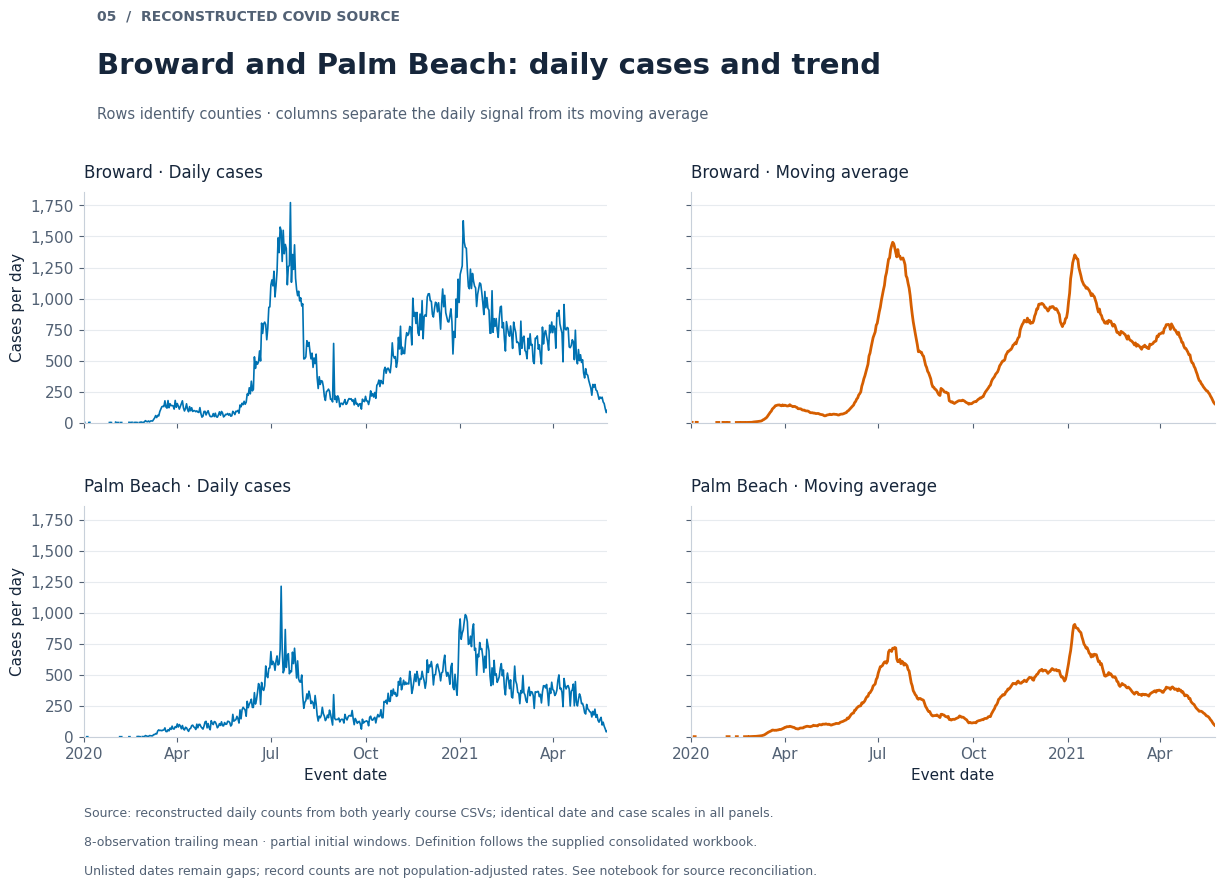

In [5]:
fig = charts.county_panels(broward, palm_beach)
assert len(fig.axes) == 4
charts.export(fig, ROOT / 'figures', '05_broward_palm_beach')
plt.show()

## Reconciliation with Combined.xlsx

The cell below compares the independently rebuilt counts with the supplied workbook over each workbook's listed dates. These sources **differ**: 278 of Pasco's 367 listed dates and 350 of Hillsborough's 370 listed dates do not match. Neither file records enough provenance to establish the reason. Requirements 2–3 therefore retain the supplied workbook, while requirements 5–6 use the original case records. No adjustments are made to force agreement.

In [6]:
comparison = compare_sources(source, config()['covid'])
comparison.to_csv(ROOT / 'reports' / 'source_crosscheck.csv', index=False)
display(comparison.groupby('county').agg(listed_dates=('date','size'), differing_dates=('matches',lambda x: (~x).sum()), total_difference=('difference','sum')))

,listed_dates,differing_dates,total_difference
county,,,
Hillsborough,370,350,-23.0
Pasco,367,278,-274.0
